# AI651 – Deep Learning for Space, Time and Graphs
# Assignment 2

Syed Obaidullah Hassan Chishti - 25280049

# Imports

In [1]:
import torch
import torchvision
import numpy as np
import copy
import cv2
import matplotlib.pyplot as plt


# Setup

## Download Dataset

In [2]:
torchvision.datasets.MovingMNIST(root='./data', split=None, download=True)

Dataset MovingMNIST
    Number of datapoints: 10000
    Root location: ./data

## Read and split data

In [2]:
# Load the file
data = np.load("data/MovingMNIST/mnist_test_seq.npy")

data = data.astype(np.float32) / 255.0  # Normalize the data to [0, 1]

train_data = data[:, :8000, :, :]
val_data = data[:, 8000:9000, :, :]
test_data = data[:, 9000:, :, :]

print("Train data shape:", train_data.shape)
print("Validation data shape:", val_data.shape)
print("Test data shape:", test_data.shape)

Train data shape: (20, 8000, 64, 64)
Validation data shape: (20, 1000, 64, 64)
Test data shape: (20, 1000, 64, 64)


# Transformations

## Mirror

In [3]:
def mirror_horizontal(x):
    j_flipped = 63 - np.arange(x.shape[-1])
    return x[..., j_flipped]

## Rotation

In [4]:
def rotate_90(x, direction='clockwise'):
    if direction == 'clockwise':
        return torch.rot90(x, k=1, dims=(-2,-1))
    elif direction == 'counterclockwise':
        return torch.rot90(x, k=-1, dims=(-2,-1))

## Speed-up

In [5]:
def speedup(x, k):
    new_n_frames = 5
    max_valid_index = 19

    input_indices = torch.arange(new_n_frames) * k
    input_indices = input_indices[input_indices <= max_valid_index]
    
    output_indices = torch.arange(new_n_frames, 2 * new_n_frames) * k
    output_indices = output_indices[output_indices <= max_valid_index]


    input_frames = x[input_indices]
    output_frames = x[output_indices]

    return input_frames, output_frames, input_indices, output_indices

## Checking the Code

In [6]:
# Define x
torch.manual_seed(0)
x = torch.rand(20, 1, 64, 64)

# Marker
p = torch.zeros_like(x)
p[7, 0, 10, 20] = 1

In [7]:
# (a) max|M (M (x)) − x|

x_mirrored = mirror_horizontal(x)
difference = torch.max(mirror_horizontal(x_mirrored) - x)
print("Difference after mirroring horizontally:", difference.item())

Difference after mirroring horizontally: 0.0


In [8]:
# (b) max|R4 (x) − x|

rotated_x = copy.deepcopy(x)
for i in range(4):
    rotated_x = rotate_90(rotated_x)

difference = torch.max(rotated_x - x)
print(f"Difference after rotating {90 * (i + 1)} degrees:", difference.item())

Difference after rotating 360 degrees: 0.0


In [9]:
# (c) max|M RM (x) − R−1 (x)|

first_mirror = mirror_horizontal(x)
first_rotate = rotate_90(first_mirror)
second_mirror = mirror_horizontal(first_rotate)

anticlockwise_rotated = rotate_90(x, direction='counterclockwise')

difference_combination = torch.max(second_mirror - anticlockwise_rotated)
print("Difference after combination of mirror and rotate:", difference_combination.item())

Difference after combination of mirror and rotate: 0.0


In [10]:
# (d) bright pixel of M (p) (frame, row, column)

mirrored_p = mirror_horizontal(p)
bright_pixel = torch.nonzero(mirrored_p, as_tuple=False)

if bright_pixel.numel() > 0:
    frame, row, column = bright_pixel[0][0].item(), bright_pixel[0][2].item(), bright_pixel[0][3].item()
    print(f"Bright pixel of M(p) is at: ({frame}, {row}, {column})")

Bright pixel of M(p) is at: (7, 10, 43)


In [11]:
# (e) bright pixel of R(p) (frame, row, column)

rotated_p = rotate_90(p)
bright_pixel = torch.nonzero(rotated_p, as_tuple=False)

if bright_pixel.numel() > 0:
    frame, row, column = bright_pixel[0][0].item(), bright_pixel[0][2].item(), bright_pixel[0][3].item()
    print(f"Bright pixel of R(p) is at: ({frame}, {row}, {column})")

Bright pixel of R(p) is at: (7, 43, 10)


In [12]:
# (f) 1× input / target frames

new_x_frames, output_frames, input_indices, output_indices = speedup(x, 1)

print("Input Frame Indices:", input_indices + 1) # Add 1 to input indices for 1-based indexing
print("Output Frame Indices:", output_indices + 1) # Add 1 to output indices for 1-based indexing


Input Frame Indices: tensor([1, 2, 3, 4, 5])
Output Frame Indices: tensor([ 6,  7,  8,  9, 10])


In [13]:
# (g) 2× input / target frames

new_x_frames, output_frames, input_indices, output_indices = speedup(x, 2)

print("Input Frame Indices:", input_indices + 1) # Add 1 to input indices for 1-based indexing
print("Output Frame Indices:", output_indices + 1) # Add 1 to output indices for 1-based indexing

Input Frame Indices: tensor([1, 3, 5, 7, 9])
Output Frame Indices: tensor([11, 13, 15, 17, 19])


In [14]:
# (h) 2× input / target frames

new_x_frames, output_frames, input_indices, output_indices = speedup(x, 3)

print("Input Frame Indices:", input_indices + 1) # Add 1 to input indices for 1-based indexing
print("Output Frame Indices:", output_indices + 1) # Add 1 to output indices for 1-based indexing


Input Frame Indices: tensor([ 1,  4,  7, 10, 13])
Output Frame Indices: tensor([16, 19])


## Is the training data already symmetric?

In [43]:

all_angles = []
all_speeds = []

for video_idx, video in enumerate(train_data[:50]):
    for s in range(19):
        prev = video[s]
        next = video[s + 1]

        prev_u8 = (prev * 255).astype(np.uint8)
        next_u8 = (next * 255).astype(np.uint8)

        flow = cv2.calcOpticalFlowFarneback(prev_u8, next_u8, None, 0.5, 3, 15, 3, 5, 1.2, 0)

        dx = flow[..., 0]
        dy = flow[..., 1]

        intensity = (prev > 0.2) & (next > 0.2)

        speed = np.sqrt(dx**2 + dy**2)

        keep = intensity & (speed > 0.5)

        angle = np.degrees(np.arctan2(-dy, dx)) % 360

        all_angles.append(angle[keep])
        all_speeds.append(speed[keep])



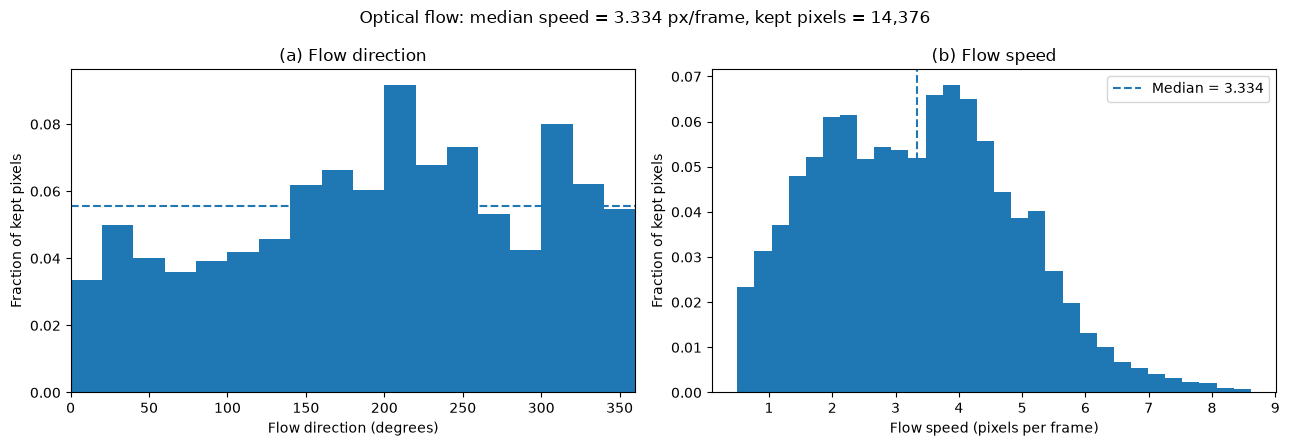

Median speed: 3.3340225
Pixels kept: 14376


In [44]:
angles = np.concatenate(all_angles)
speeds = np.concatenate(all_speeds)

median_speed = np.median(speeds)
n_kept = len(speeds)

# Plot both histograms
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# (a) Direction: 18 bins, each 20 degrees
axes[0].hist(
    angles,
    bins=np.linspace(0, 360, 19),
    weights=np.ones(len(angles)) / n_kept
)
axes[0].axhline(1 / 18, linestyle="--")
axes[0].set(
    xlabel="Flow direction (degrees)",
    ylabel="Fraction of kept pixels",
    title="(a) Flow direction",
    xlim=(0, 360)
)

# (b) Speed
axes[1].hist(
    speeds,
    bins=30,
    weights=np.ones(n_kept) / n_kept
)
axes[1].axvline(
    median_speed,
    linestyle="--",
    label=f"Median = {median_speed:.3f}"
)
axes[1].set(
    xlabel="Flow speed (pixels per frame)",
    ylabel="Fraction of kept pixels",
    title="(b) Flow speed"
)
axes[1].legend()

fig.suptitle(
    f"Optical flow: median speed = {median_speed:.3f} px/frame, "
    f"kept pixels = {n_kept:,}"
)
fig.tight_layout()
plt.show()

print("Median speed:", median_speed)
print("Pixels kept:", n_kept)
